# 10 · BTC market regimes with past-only rules

Module **M5: regimes** (Phase 1).

**Task.** Describe BTC market regimes with three simple rules that only use the past. This notebook
is **descriptive, not predictive**: there are no trading rules here and no claims about the future.

**Hypotheses (written before results).** No prior hypotheses were recorded.

**Market.** Binance **spot** BTC/USDT, daily candles, from the first day Binance has
(2017-08-17, see Part 0) to the last complete UTC day, 2026-11-24. The daily close is the last trade
before the 00:00 UTC boundary, the same as notebook 09.

**Questions (one row each in the Findings table at the end).**

| | Question |
|---|---|
| Q1 | Are the three rules free of look-ahead (truncation test)? How much would a full-sample rule change the labels? |
| Q2 | How much time does BTC spend in each regime, under each rule? |
| Q3 | How long do regimes last (complete episodes only)? |
| Q4 | What does the **next-day** return look like after each label, and how much of it comes from a single episode? |
| Q5 | How do the three rules overlap? |
| Q6 | How often does the MA200 label flip, with and without the ±2% band, and what would that cost (assumed)? |
| Q7 | How often do the expanding and rolling volatility labels disagree? |
| Q8 | Does the 30-day σ window leave a mark on how long volatility episodes last? |
| Q9 | What is the regime today, under every rule? |

**Pre-specified parameters (fixed before seeing results; any later change is labelled "post-inspection").**

1. **Trend.** Close of day t vs the 200-day simple moving average of the closes up to and
   including day t. No label before 200 closes exist. Sensitivity version: a **±2% band**, where the
   label switches only when the close crosses the MA by more than 2%.
2. **Volatility.** σ30 = the past-only 30-day σ from notebook 09 (std of the 30 daily returns
   before day t, annualized with √365). Labels **low / mid / high** by terciles, with thresholds
   computed only from σ values on days ≤ t:
   (a) **expanding** thresholds (all σ history so far, at least 365 days);
   (b) **rolling** thresholds (the last 730 days).
3. **Drawdown** from the running max (the highest close up to day t). Bands: **near-ATH** (0 to
   −10%), **correction** (−10% to −30%), **deep bear** (below −30%).

**Timing.** A label is known at the **close of day t**. Any return attributed to a regime is the
**next-day** return, close t → close t+1. A same-day return (close t−1 → close t) is shown only in a
column labelled "mechanical (same-day)". For the trend and drawdown rules the label already "saw"
that return (it uses close t), so it is not a fair measure of anything. The volatility labels use σ
up to day t−1, so they did not see it.

**Simple return:** $r_t = \text{close}_t / \text{close}_{t-1} - 1$ (not logarithmic). 1 bp = 0.01%.

## 0. Setup and data

The downloader is the same one notebooks 01–09 use (`src/data/ohlcv.py`, through ccxt). Notebook
09's cache starts on 2018-01-01, but this notebook needs the first day Binance has, so it downloads
a longer window into `data/10_regimes/` (gitignored) and checks that it matches 09's cache on every
day they share. The returns, the past-only σ and the annualization are imported from
`src/volatility.py` (tested in 09); the new regime helpers are in `src/regimes.py`.

In [1]:
%matplotlib inline
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data.ohlcv import cache_path, fetch_ohlcv_window, load_or_fetch_window
from src.regimes import (ABOVE, BELOW, CORRECTION, DEEP_BEAR, HIGH, LOW, MID, NEAR_ATH,
                         drawdown_from_running_max, drawdown_label, episode_summary, episodes,
                         expanding_tercile_thresholds, flips, flips_per_year, ma_trend_band_label,
                         ma_trend_label, next_day_stats, rolling_tercile_thresholds,
                         simple_moving_average, tercile_label, truncation_mismatches)
from src.volatility import DAYS_PER_YEAR, annualize, past_only_sigma, step_returns

DATA_DIR = REPO_ROOT / "data" / "10_regimes"
CACHE_09 = REPO_ROOT / "data" / "09_volatility" / "binance_BTCUSDT_1d_2018-01-01_2026-11-23_last.parquet"
START_UTC = "2017-08-01"          # before Binance's first BTC/USDT day, so we get all of it
END_UTC = "2026-11-25"            # excluded: the last candle kept opens on 2026-11-24
NOW_UTC = "2026-11-25 00:05"      # fixed "now", so a re-run drops exactly the same candles
LABEL = "2017-08-01_2026-11-24"   # part of the cache file name
DAY = pd.Timedelta(days=1)

# Pre-specified parameters (see the introduction)
MA_WINDOW = 200
BAND = 0.02
SIGMA_WINDOW = 30
EXPANDING_MIN = 365
ROLLING_WINDOW = 730
DD_CORRECTION, DD_DEEP = -0.10, -0.30
SHORT_DAYS = 5
COST_RT_BPS = 20.0                # ASSUMED: spot taker -> taker round trip from notebook 07
TRUNCATION_CUTOFFS = ["2019-12-31", "2021-12-31", "2023-12-31"]   # + last day - 365, below

HALVINGS = ["2020-05-11", "2024-04-20"]
EVENTS = {"2025-10-10": "2025-10-10"}   # marked as in notebook 09; not a halving

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
BLUE, ORANGE = "#2a78d6", "#eb6834"                     # categorical slots 1 and 2 (as in 09)
SEQ = {LOW: "#b7d3f6", MID: "#5598e7", HIGH: "#184f95"}  # one blue ramp, light -> dark
TREND_FILL = {ABOVE: BLUE, BELOW: ORANGE}
DD_FILL = {NEAR_ATH: "#cde2fb", CORRECTION: "#86b6ef", DEEP_BEAR: "#256abf"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
path = cache_path(DATA_DIR, "binance", "BTC/USDT", "1d", LABEL)
candles, info = load_or_fetch_window(
    path, lambda: fetch_ohlcv_window("binance", "BTC/USDT", START_UTC, END_UTC,
                                     timeframe="1d", now_utc=NOW_UTC))
close = candles["close"].asfreq("D")          # regular daily grid (NaN if a day were missing)
FIRST_DAY, LAST_DAY = close.index.min(), close.index.max()
TRUNCATION_CUTOFFS = TRUNCATION_CUTOFFS + [str((LAST_DAY - 365 * DAY).date())]

expected = pd.date_range(FIRST_DAY, LAST_DAY, freq="D")
if CACHE_09.exists():           # cross-check with notebook 09's cache, if 09 was run
    old = pd.read_parquet(CACHE_09)["close"]
    shared = close.index.intersection(old.index)
    n_shared, max_diff = len(shared), float((close.loc[shared] - old.loc[shared]).abs().max())
else:
    n_shared, max_diff = "skipped (no 09 cache)", "skipped"
pd.DataFrame([{
    "first open (UTC)": FIRST_DAY, "last open (UTC)": LAST_DAY, "candles": int(close.notna().sum()),
    "missing days": len(expected.difference(candles.index)),
    "duplicates dropped": info["duplicates_dropped"], "incomplete dropped": info["incomplete_dropped"],
    "days shared with 09 cache": n_shared,
    "max |close − 09 close| (USDT)": max_diff,
}]).T.rename(columns={0: "BTC/USDT 1d"})

,BTC/USDT 1d
first open (UTC),2017-08-17 00:00:00+00:00
last open (UTC),2026-11-24 00:00:00+00:00
candles,3387
missing days,0
duplicates dropped,0
incomplete dropped,0
days shared with 09 cache,3249
max |close − 09 close| (USDT),0.0


### 0.1 Returns, σ30 and the five labels

`compute_labels` builds every label from the closes alone, so the truncation test in Part 1 can
call it again on a shorter history. Each rule only uses rolling or expanding windows that end on
day t.

Note on σ30: the past-only σ from 09 at day t uses the 30 returns **before** t, so on day t it is
already one day old. That is stricter than needed (the label is only used at the close of t), and
it is kept as is because the brief asks to reuse the tested function.

Implementation choice (made before results): with the ±2% band, the first label after the warm-up
appears on the first day the close is more than 2% away from the MA.

In [3]:
RULES = {                                   # column name -> display name
    "trend": "trend (MA200)",
    "trend_band": "trend (MA200 ±2% band)",
    "vol_exp": "vol (expanding terciles)",
    "vol_roll": "vol (rolling 730-d terciles)",
    "dd": "drawdown",
}
ORDER = {"trend": [ABOVE, BELOW], "trend_band": [ABOVE, BELOW], "vol_exp": [LOW, MID, HIGH],
         "vol_roll": [LOW, MID, HIGH], "dd": [NEAR_ATH, CORRECTION, DEEP_BEAR]}


def compute_parts(close):
    # Every series needed for the labels, from the daily closes only.
    r = step_returns(close, DAY).reindex(close.index)
    sigma = annualize(past_only_sigma(r, SIGMA_WINDOW), DAYS_PER_YEAR)
    return {"r": r, "ma": simple_moving_average(close, MA_WINDOW), "sigma": sigma,
            "th_exp": expanding_tercile_thresholds(sigma, EXPANDING_MIN),
            "th_roll": rolling_tercile_thresholds(sigma, ROLLING_WINDOW),
            "dd": drawdown_from_running_max(close)}


def compute_labels(close):
    p = compute_parts(close)
    return pd.DataFrame({
        "trend": ma_trend_label(close, MA_WINDOW),
        "trend_band": ma_trend_band_label(close, MA_WINDOW, BAND),
        "vol_exp": tercile_label(p["sigma"], p["th_exp"]),
        "vol_roll": tercile_label(p["sigma"], p["th_roll"]),
        "dd": drawdown_label(p["dd"], DD_CORRECTION, DD_DEEP),
    })


parts = compute_parts(close)
r, sigma = parts["r"], parts["sigma"]
labels = compute_labels(close)

pd.DataFrame([{"rule": RULES[c], "first labelled day": labels[c].first_valid_index().date(),
               "labelled days": int(labels[c].notna().sum()),
               "unlabelled (warm-up)": int(labels[c].isna().sum())} for c in RULES]).set_index("rule")

,first labelled day,labelled days,unlabelled (warm-up)
rule,,,
trend (MA200),2018-03-04,3188,199
trend (MA200 ±2% band),2018-03-04,3188,199
vol (expanding terciles),2018-09-16,2992,395
vol (rolling 730-d terciles),2019-09-16,2627,760
drawdown,2017-08-17,3387,0


## 1. Look-ahead checks

**Truncation test.** For each cutoff D, every label is recomputed from the closes up to D only.
If a rule uses only the past, every label on a day ≤ D must be the same as with the full data.
The table counts the days that differ; the code stops (`assert`) if any rule fails.

In [4]:
trunc = pd.DataFrame({D: {RULES[c]: truncation_mismatches(lambda x, c=c: compute_labels(x)[c], close, D)
                          for c in RULES} for D in TRUNCATION_CUTOFFS})
trunc["result"] = np.where(trunc.sum(axis=1) == 0, "pass", "FAIL")
assert (trunc["result"] == "pass").all(), "a rule uses data after day t"
trunc.rename_axis("days ≤ D whose label changes")

,2019-12-31,2021-12-31,2023-12-31,2025-11-24,result
days ≤ D whose label changes,,,,,
trend (MA200),0,0,0,0,pass
trend (MA200 ±2% band),0,0,0,0,pass
vol (expanding terciles),0,0,0,0,pass
vol (rolling 730-d terciles),0,0,0,0,pass
drawdown,0,0,0,0,pass


**Illustration only — look-ahead, do not use.** The same tercile rule, but with the thresholds
computed from **all** σ values of 2017–2026 at once. On any past day, that version used σ values
that did not exist yet. The table shows the % of days whose label differs from the past-only
version (a), by year, on the days where (a) has a label.

In [5]:
q_full = sigma.quantile([1 / 3, 2 / 3]).to_numpy()
th_full = pd.DataFrame({"q1": q_full[0], "q2": q_full[1]}, index=sigma.index)
vol_lookahead = tercile_label(sigma, th_full)

both = labels["vol_exp"].notna() & vol_lookahead.notna()
differs = (labels["vol_exp"] != vol_lookahead)[both]
lookahead_by_year = pd.DataFrame({
    "days": differs.groupby(differs.index.year).size(),
    "% days label differs": 100 * differs.groupby(differs.index.year).mean(),
})
lookahead_by_year.loc["all"] = [len(differs), 100 * differs.mean()]


def full_sample_vol_label(x):
    # LOOK-AHEAD on purpose: thresholds from every σ value in x, including later ones.
    sig = compute_parts(x)["sigma"]
    th = pd.DataFrame({"q1": sig.quantile(1 / 3), "q2": sig.quantile(2 / 3)}, index=x.index)
    return tercile_label(sig, th)


lookahead_trunc = truncation_mismatches(full_sample_vol_label, close, TRUNCATION_CUTOFFS[1])
print(f"full-sample thresholds (look-ahead): q1 = {q_full[0]:.1%}, q2 = {q_full[1]:.1%}")
print(f"truncation test at {TRUNCATION_CUTOFFS[1]} on the look-ahead version: "
      f"{lookahead_trunc} days change -> FAIL, as it should")
lookahead_by_year.round(1).astype({"days": int}).rename_axis("year (look-ahead — do not use)")

full-sample thresholds (look-ahead): q1 = 45.9%, q2 = 66.4%
truncation test at 2021-12-31 on the look-ahead version: 677 days change -> FAIL, as it should


,days,% days label differs
year (look-ahead — do not use),,
2018,107,44.9
2019,365,66.3
2020,366,57.4
2021,365,36.7
2022,365,46.6
2023,365,28.8
2024,366,38.3
2025,365,9.9
2026,328,0.9


## 2. The three rules over time

### 2.1 Trend: log price, MA200 and the regime

Blue background = close above the MA200, orange = below (plain rule, no band). The vertical lines
mark the two halvings in this data and the 2025-10-10 date used in notebook 09. With only 2
halvings, nothing can be concluded about them here.

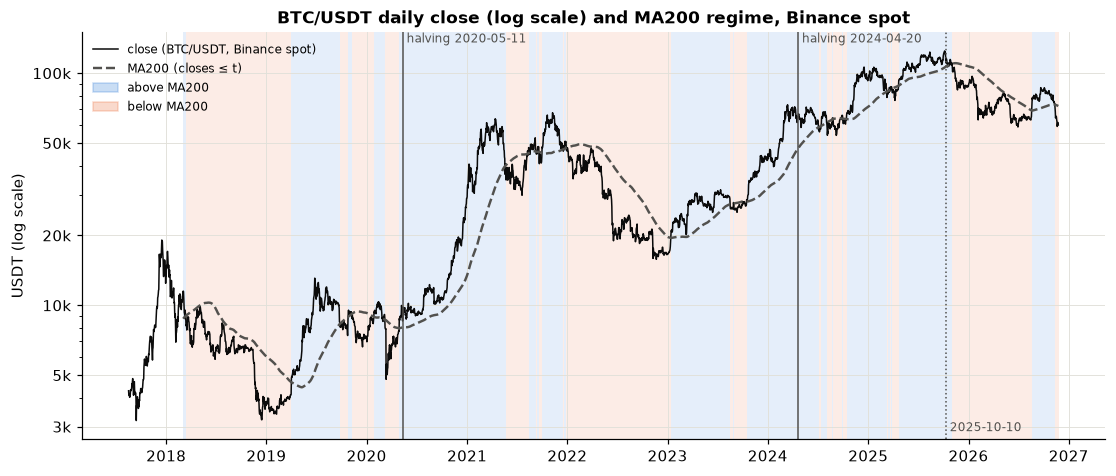

In [6]:
def shade(ax, lab, colors, alpha):
    for _, e in episodes(lab).iterrows():
        ax.axvspan(e["start"], e["end"] + DAY, color=colors[e["label"]], alpha=alpha, lw=0)


fig, ax = plt.subplots(figsize=(12, 4.8))
shade(ax, labels["trend"], TREND_FILL, 0.12)
ax.plot(close.index, close, color=INK, lw=1.0, label="close (BTC/USDT, Binance spot)")
ax.plot(parts["ma"].index, parts["ma"], color=MUTED, lw=1.6, ls="--", label="MA200 (closes ≤ t)")
ax.set_yscale("log")
ax.set_yticks([3e3, 5e3, 1e4, 2e4, 5e4, 1e5])
ax.set_yticklabels(["3k", "5k", "10k", "20k", "50k", "100k"])
for d in HALVINGS:
    ax.axvline(pd.Timestamp(d, tz="UTC"), color=MUTED, lw=1)
    ax.text(pd.Timestamp(d, tz="UTC"), ax.get_ylim()[1], f" halving {d}", va="top", fontsize=8, color=MUTED)
for d, name in EVENTS.items():
    ax.axvline(pd.Timestamp(d, tz="UTC"), color=MUTED, lw=1, ls=":")
    ax.text(pd.Timestamp(d, tz="UTC"), ax.get_ylim()[0] * 1.05, f" {name}", va="bottom", fontsize=8, color=MUTED)
handles = ax.get_legend_handles_labels()[0] + [Patch(color=BLUE, alpha=0.25, label="above MA200"),
                                               Patch(color=ORANGE, alpha=0.25, label="below MA200")]
ax.legend(handles=handles, loc="upper left", fontsize=8, frameon=False)
ax.set_title("BTC/USDT daily close (log scale) and MA200 regime, Binance spot")
ax.set_ylabel("USDT (log scale)")
plt.show()

### 2.2 Volatility: σ30 and the tercile thresholds

σ30 is annualized (× √365), in %. Blue = expanding thresholds (all history up to t), orange =
rolling thresholds (last 730 days). Dashed = lower tercile (below it: "low"), solid = upper tercile
(above it: "high").

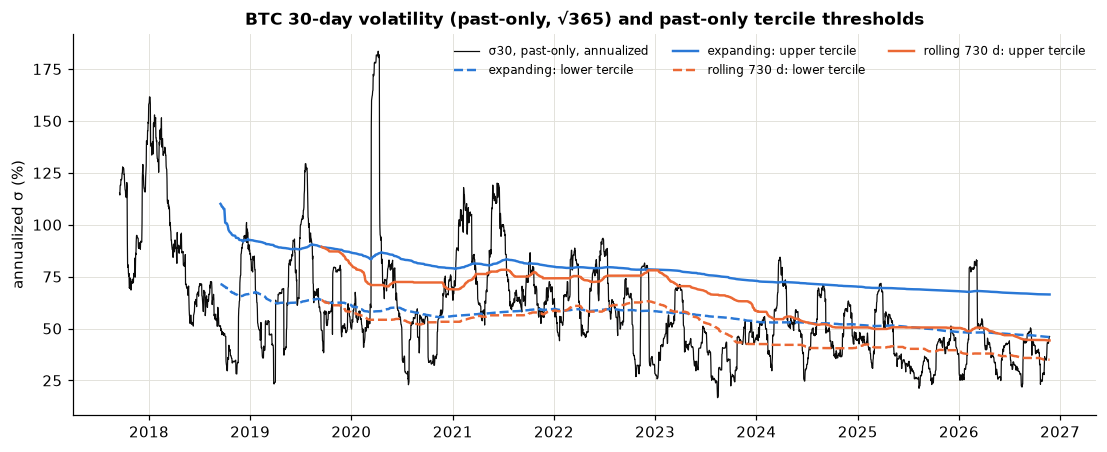

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(sigma.index, 100 * sigma, color=INK, lw=0.8, label="σ30, past-only, annualized")
for th, color, name in [(parts["th_exp"], BLUE, "expanding"), (parts["th_roll"], ORANGE, "rolling 730 d")]:
    ax.plot(th.index, 100 * th["q1"], color=color, lw=1.6, ls="--", label=f"{name}: lower tercile")
    ax.plot(th.index, 100 * th["q2"], color=color, lw=1.6, label=f"{name}: upper tercile")
ax.set_ylabel("annualized σ (%)")
ax.set_title("BTC 30-day volatility (past-only, √365) and past-only tercile thresholds")
ax.legend(loc="upper right", fontsize=8, frameon=False, ncol=3)
plt.show()

### 2.3 Drawdown from the running max

The drawdown is 0% on a day with a new highest close and negative otherwise. The bands are the
three labels. The running max starts on 2017-08-17: it does not know any price before Binance's
first day.

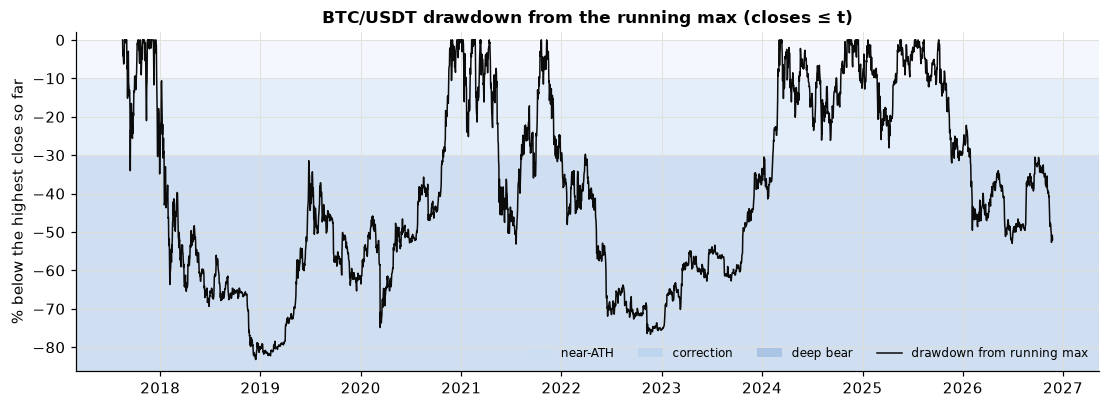

In [8]:
dd = parts["dd"]
fig, ax = plt.subplots(figsize=(12, 4))
for lo, hi, lab in [(DD_CORRECTION, 0.0, NEAR_ATH), (DD_DEEP, DD_CORRECTION, CORRECTION), (-1.0, DD_DEEP, DEEP_BEAR)]:
    ax.axhspan(100 * lo, 100 * hi, color=DD_FILL[lab], alpha=0.22, lw=0, label=lab)
ax.plot(dd.index, 100 * dd, color=INK, lw=1.0, label="drawdown from running max")
ax.set_ylim(100 * dd.min() - 3, 2)
ax.set_ylabel("% below the highest close so far")
ax.set_title("BTC/USDT drawdown from the running max (closes ≤ t)")
ax.legend(loc="lower right", fontsize=8, frameon=False, ncol=4)
plt.show()

## 3. Time in each regime and how long regimes last

**Time in regime:** % of the labelled days of each rule (the warm-up days are not counted).

In [9]:
rows = []
for c, name in RULES.items():
    lab = labels[c].dropna()
    for v in ORDER[c]:
        rows.append({"rule": name, "label": v, "n days": int((lab == v).sum()),
                     "% of labelled days": 100 * (lab == v).mean()})
time_in = pd.DataFrame(rows).set_index(["rule", "label"])
time_in.round(1)

n days  % of labelled days
rule                         label                                 
trend (MA200)                above MA      1680                52.7
                             below MA      1508                47.3
trend (MA200 ±2% band)       above MA      1686                52.9
                             below MA      1502                47.1
vol (expanding terciles)     low           1750                58.5
                             mid            864                28.9
                             high           378                12.6
vol (rolling 730-d terciles) low           1074                40.9
                             mid            922                35.1
                             high           631                24.0
drawdown                     near-ATH       607                17.9
                             correction     578                17.1
                             deep bear     2202                65.0

**Episodes.** An episode is a run of consecutive days with the same label. The first episode of each
rule is **censored at the start** (we do not see when it really began) and the one still running
on 2026-11-24 is **censored at the end**. Durations (median / p90 / max) use **complete** episodes
only. "Short" = fewer than 5 days.

In [10]:
eps = {c: episodes(labels[c]) for c in RULES}
ep_table = pd.concat({RULES[c]: episode_summary(eps[c], SHORT_DAYS).reindex(ORDER[c]) for c in RULES},
                     names=["rule", "label"])
ep_table

n episodes  n censored (first)  n censored (last)  n short (< 5 d)  n complete  median days (complete)  \
rule                         label                                                                                                                
trend (MA200)                above MA            33                   1                  0               15          32                     5.5   
                             below MA            33                   0                  1               17          32                     3.5   
trend (MA200 ±2% band)       above MA            17                   1                  0                0          16                    58.0   
                             below MA            17                   0                  1                2          16                    41.0   
vol (expanding terciles)     low                 43                   1                  0               15          42                    22.5   
                             mid                 65                   0                  1               22          64                     8.0   
                             high                22                   0                  0                6          22                     7.0   
vol (rolling 730-d terciles) low                 45                   1                  0               20          44                     8.0   
                             mid                 74                   0                  0               25          74                     6.5   
                             high                31                   0                  1                9          30                    12.5   
drawdown                     near-ATH            42                   1                  0               19          41                     6.0   
                             correction          66                   0                  0               36          66                     3.0   
                             deep bear           25                   0                  1               19          24                     1.0   

                                         p90 days (complete)  max days (complete)  
rule                         label                                                 
trend (MA200)                above MA                  177.9                  385  
                             below MA                   80.9                  384  
trend (MA200 ±2% band)       above MA                  237.5                  385  
                             below MA                  335.0                  384  
vol (expanding terciles)     low                        80.0                  285  
                             mid                        30.0                   58  
                             high                       45.1                   62  
vol (rolling 730-d terciles) low                        41.4                  194  
                             mid                        29.4                   73  
                             high                       46.7                   79  
drawdown                     near-ATH                   35.0                  111  
                             correction                 21.5                   66  
                             deep bear                  84.1                 1015

## 4. Next-day returns by regime

For each label: the return from close t to close t+1, after a day with that label. Mean and median
in bps, daily σ in %. "ex-worst" drops the label's single worst episode (the one with the lowest
compounded next-day return). The SE column assumes independent days, so it **understates** the
real noise when volatility clusters. The last column is **mechanical (same-day)**: the return of
day t itself. For the trend and drawdown rules the label used close t, so that return is
mechanical. The volatility labels use σ up to t−1, so for them the same-day return was not seen by
the label and comes out close to the next-day one.

Each rule has its own baseline (the mean over all its labelled days), since the rules start on
different dates. With 13 label rows, a gap of about 2 SE from the baseline is expected somewhere by
chance alone, even before volatility clustering widens the noise.

In [11]:
nd = pd.concat({RULES[c]: next_day_stats(labels[c], r).reindex(ORDER[c]) for c in RULES},
               names=["rule", "label"])
base_rows = []
for c in RULES:
    x = r.shift(-1)[labels[c].notna()].dropna()
    base_rows.append({"rule": RULES[c], "first labelled day": labels[c].first_valid_index().date(),
                      "mean next-day (bps)": 1e4 * x.mean(), "median next-day (bps)": 1e4 * x.median(),
                      "SE of mean, i.i.d. (bps)": 1e4 * x.std() / math.sqrt(len(x)), "n days": len(x)})
baseline = pd.DataFrame(base_rows).set_index("rule")
display(baseline.round(1).rename_axis("baseline: all labelled days of each rule"))
nd.round(1)

,first labelled day,mean next-day (bps),median next-day (bps),"SE of mean, i.i.d. (bps)",n days
baseline: all labelled days of each rule,,,,,
trend (MA200),2018-03-04,10.5,3.1,5.7,3187
trend (MA200 ±2% band),2018-03-04,10.5,3.1,5.7,3187
vol (expanding terciles),2018-09-16,12.7,3.1,5.9,2991
vol (rolling 730-d terciles),2019-09-16,11.7,1.6,6.1,2626
drawdown,2017-08-17,13.9,4.7,6.0,3386


mean next-day (bps)  median next-day (bps)  daily σ next-day (%)  SE of mean, i.i.d. (bps)  n days  n episodes  \
rule                         label                                                                                                                        
trend (MA200)                above MA                   16.4                    7.1                   3.1                       7.5    1680          33   
                             below MA                    3.9                   -0.6                   3.4                       8.8    1507          33   
trend (MA200 ±2% band)       above MA                   18.4                    8.0                   3.1                       7.5    1686          17   
                             below MA                    1.6                   -1.9                   3.4                       8.8    1501          17   
vol (expanding terciles)     low                         5.9                    1.0                   2.6                       6.3    1750          43   
                             mid                        26.5                   19.4                   3.7                      12.7     863          65   
                             high                       12.6                   -4.5                   4.2                      21.7     378          22   
vol (rolling 730-d terciles) low                         2.0                   -3.6                   2.6                       8.0    1074          45   
                             mid                        13.0                    2.5                   3.3                      11.0     922          74   
                             high                       26.5                   19.8                   3.6                      14.5     630          31   
drawdown                     near-ATH                   34.7                    7.1                   3.3                      13.4     607          42   
                             correction                  7.2                    6.8                   3.7                      15.6     578          66   
                             deep bear                  10.0                    3.2                   3.5                       7.4    2201          25   

                                        worst episode start  worst episode compounded (%)  mean next-day ex-worst (bps)  median next-day ex-worst (bps)  \
rule                         label                                                                                                                        
trend (MA200)                above MA            2018-03-04                         -23.8                          18.0                             8.0   
                             below MA            2021-12-28                         -58.1                          11.1                             4.5   
trend (MA200 ±2% band)       above MA            2018-03-04                         -29.0                          20.5                             8.8   
                             below MA            2021-12-29                         -57.1                           7.8                             2.6   
vol (expanding terciles)     low                 2018-09-16                         -37.2                           8.7                             1.1   
                             mid                 2020-03-09                         -29.7                          29.3                            19.4   
                             high                2021-05-13                         -33.9                          25.5                            -0.7   
vol (rolling 730-d terciles) low                 2022-04-04                         -33.4                           5.8                            -3.5   
                             mid                 2020-03-09                         -29.7                          15.6                             2.5   
          

## 5. How the three rules overlap

% of days in each combination of trend (plain MA200), drawdown and volatility (expanding), on days
where all three have a label. The whole table sums to 100%.

In [12]:
lab3 = labels[["trend", "dd", "vol_exp"]].dropna()
cross = pd.crosstab([lab3["trend"], lab3["dd"]], lab3["vol_exp"], normalize="all") * 100
cross = cross.reindex(columns=ORDER["vol_exp"])
cross = cross.reindex(pd.MultiIndex.from_product([ORDER["trend"], ORDER["dd"]]), fill_value=0.0)
cross["row total"] = cross.sum(axis=1)
print(f"days with all three labels: {len(lab3)} ({lab3.index.min().date()} → {lab3.index.max().date()})")
cross.rename_axis(index=["trend", "drawdown"], columns="vol (expanding)").round(1)

days with all three labels: 2992 (2018-09-16 → 2026-11-24)


vol (expanding)       low  mid  high  row total
trend    drawdown                              
above MA near-ATH     9.7  5.8   1.6       17.2
         correction   4.6  4.4   1.7       10.8
         deep bear   19.1  6.9   1.9       27.8
below MA near-ATH     0.0  0.0   0.0        0.0
         correction   4.1  2.4   0.1        6.7
         deep bear   21.0  9.3   7.3       37.5

## 6. MA200 flips per year and an assumed cost

A flip is a day whose label differs from the day before. If someone switched between holding BTC
and holding USDT on every flip, two flips would be one round trip. The cost column uses an
**assumed** 20 bps per round trip (spot taker → taker from notebook 07), so cost = (flips / 2) ×
20 bps of the position per year. This is an illustration of churn, not a strategy test. 2018 and
2026 are partial years.

In [13]:
fl = pd.DataFrame({
    "labelled days": labels["trend"].notna().groupby(labels.index.year).sum(),
    "flips (plain)": flips_per_year(labels["trend"]),
    "flips (±2% band)": flips_per_year(labels["trend_band"]),
}).fillna(0).astype(int)
fl = fl[fl["labelled days"] > 0]
fl.loc["all"] = fl.sum()
fl["ASSUMED cost plain (bps)"] = fl["flips (plain)"] / 2 * COST_RT_BPS
fl["ASSUMED cost band (bps)"] = fl["flips (±2% band)"] / 2 * COST_RT_BPS
fl.rename_axis("year")

,labelled days,flips (plain),flips (±2% band),ASSUMED cost plain (bps),ASSUMED cost band (bps)
year,,,,,
2018,303,3,1,30.0,10.0
2019,365,4,4,40.0,40.0
2020,366,5,5,50.0,50.0
2021,365,19,7,190.0,70.0
2022,365,0,0,0.0,0.0
2023,365,5,3,50.0,30.0
2024,366,10,6,100.0,60.0
2025,365,17,5,170.0,50.0
2026,328,2,2,20.0,20.0


## 7. Expanding vs rolling volatility labels

% of days where the two versions give a different label, on days where both have one.

In [14]:
both_vol = labels[["vol_exp", "vol_roll"]].dropna()
disagree = both_vol["vol_exp"] != both_vol["vol_roll"]
recent = disagree.index.year >= 2024
vol_cmp = pd.DataFrame([
    {"period": f"all ({both_vol.index.min().date()} → {both_vol.index.max().date()})",
     "n days": len(disagree), "% disagree": 100 * disagree.mean()},
    {"period": "2024–2026", "n days": int(recent.sum()), "% disagree": 100 * disagree[recent].mean()},
]).set_index("period")
print(f"today ({LAST_DAY.date()}): expanding = {labels['vol_exp'].iloc[-1]}, "
      f"rolling = {labels['vol_roll'].iloc[-1]}")
display(vol_cmp.round(1))
pd.crosstab(both_vol["vol_exp"], both_vol["vol_roll"]).reindex(index=ORDER["vol_exp"], columns=ORDER["vol_roll"]) \
    .rename_axis(index="expanding ↓ / rolling →", columns=None)

today (2026-11-24): expanding = mid, rolling = high


,n days,% disagree
period,,
all (2019-09-16 → 2026-11-24),2627,31.3
2024–2026,1059,53.2


,low,mid,high
expanding ↓ / rolling →,,,
low,1070,497,10
mid,4,425,310
high,0,0,311


## 8. Window-step check

A single large return stays inside the 30-day σ window for exactly 30 days and then drops out, so
σ30 tends to jump up on the day after a big move and jump down 30 days later. If that mechanical
step drives the labels, volatility episodes lasting about 30 days should be more common than
episodes of 25 or 35 days. The counts use all episodes (censored included).

The counts are small, so the table adds a rough check (added after the review). Suppose 28–32 days
were no more likely than its neighbours. Then the count would be roughly Poisson, with mean λ = the
average of the 23–27 and 33–37 counts. The last column is P(count ≥ observed) under that
assumption. It is a rough guide, not a formal test.

,all episodes,23–27 d,28–32 d,33–37 d,λ (neighbour average),P(≥ observed 28–32)
rule,,,,,,
vol (expanding terciles),130,6,13,3,4.5,0.0008
vol (rolling 730-d terciles),150,4,15,5,4.5,0.0001


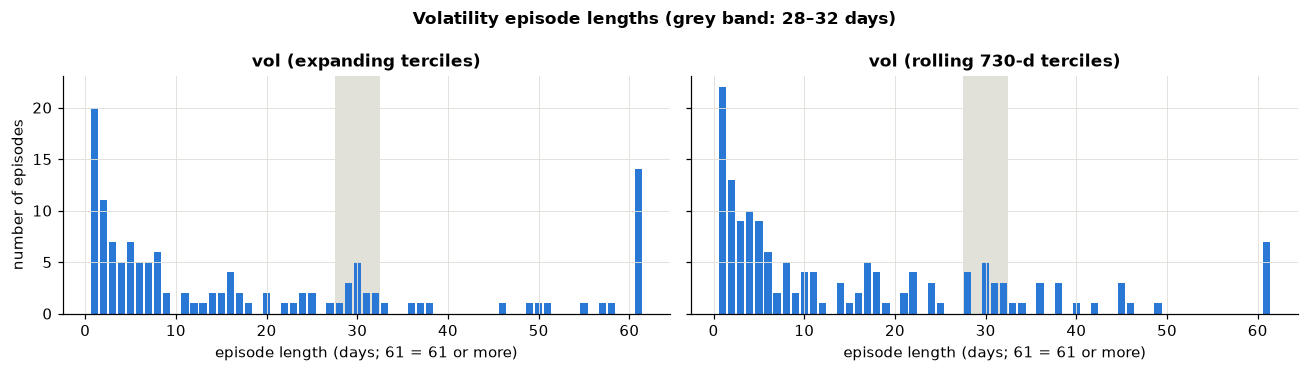

In [15]:
bins = {"23–27 d": (23, 27), "28–32 d": (28, 32), "33–37 d": (33, 37)}
step_rows = []
for c in ["vol_exp", "vol_roll"]:
    n = eps[c]["n_days"]
    row = {"rule": RULES[c], "all episodes": len(n)}
    row.update({k: int(n.between(lo, hi).sum()) for k, (lo, hi) in bins.items()})
    step_rows.append(row)
step_table = pd.DataFrame(step_rows).set_index("rule")


def poisson_tail(k, lam):
    # P(X >= k) for X ~ Poisson(lam)
    return 1 - sum(math.exp(-lam) * lam ** i / math.factorial(i) for i in range(k))


step_table["λ (neighbour average)"] = (step_table["23–27 d"] + step_table["33–37 d"]) / 2
step_table["P(≥ observed 28–32)"] = [poisson_tail(k, lam) for k, lam in
                                     zip(step_table["28–32 d"], step_table["λ (neighbour average)"])]
display(step_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, c in zip(axes, ["vol_exp", "vol_roll"]):
    counts = eps[c]["n_days"].clip(upper=61).value_counts().reindex(range(1, 62), fill_value=0)
    ax.axvspan(27.5, 32.5, color=GRID, lw=0)
    ax.bar(counts.index, counts.values, width=0.8, color=BLUE)
    ax.set_title(RULES[c])
    ax.set_xlabel("episode length (days; 61 = 61 or more)")
axes[0].set_ylabel("number of episodes")
fig.suptitle("Volatility episode lengths (grey band: 28–32 days)", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

## 9. Current state

The label on the last complete day under every rule and version, with the numbers behind it.
"Days in this episode" counts back to the last label change (the episode is still running, so it
is censored).

In [16]:
t = LAST_DAY
th_e, th_r = parts["th_exp"].loc[t], parts["th_roll"].loc[t]
detail = {
    "trend": f"close {close[t]:,.0f} vs MA200 {parts['ma'][t]:,.0f} ({close[t] / parts['ma'][t] - 1:+.1%})",
    "trend_band": f"band ±2%: {parts['ma'][t] * (1 - BAND):,.0f} – {parts['ma'][t] * (1 + BAND):,.0f}",
    "vol_exp": f"σ30 {sigma[t]:.1%}; terciles {th_e['q1']:.1%} / {th_e['q2']:.1%}",
    "vol_roll": f"σ30 {sigma[t]:.1%}; terciles {th_r['q1']:.1%} / {th_r['q2']:.1%}",
    "dd": f"drawdown {parts['dd'][t]:.1%} (max close {close[:t].max():,.0f} on {close[:t].idxmax().date()})",
}
current = pd.DataFrame([{"rule": RULES[c], "label on " + str(t.date()): labels[c][t],
                         "days in this episode": int(eps[c]["n_days"].iloc[-1]),
                         "episode started": eps[c]["start"].iloc[-1].date(), "numbers": detail[c]}
                        for c in RULES]).set_index("rule")
current["days in this episode"] = current["days in this episode"].astype("Int64")
current.loc["vol (full-sample terciles) — look-ahead, do not use"] = [
    vol_lookahead[t], pd.NA, None, f"terciles {q_full[0]:.1%} / {q_full[1]:.1%}"]
current

,label on 2026-11-24,days in this episode,episode started,numbers
rule,,,,
trend (MA200),below MA,13,2026-11-12,"close 59,832 vs MA200 72,189 (-17.1%)"
trend (MA200 ±2% band),below MA,13,2026-11-12,"band ±2%: 70,746 – 73,633"
vol (expanding terciles),mid,2,2026-11-23,σ30 46.1%; terciles 45.9% / 66.4%
vol (rolling 730-d terciles),high,4,2026-11-21,σ30 46.1%; terciles 35.0% / 44.3%
drawdown,deep bear,300,2026-01-29,"drawdown -52.0% (max close 124,659 on 2025-10-06)"
"vol (full-sample terciles) — look-ahead, do not use",mid,<NA>,NaN,terciles 45.9% / 66.4%


## Findings

One row per question. **Measured** = computed from the candles in this notebook. **Assumed** =
taken from elsewhere or from a rule that is not checked here. "n" gives days and episodes.

In [17]:
def ep_n(c):
    return len(eps[c])


ti = time_in["% of labelled days"]
cmp_ = ep_table["median days (complete)"]
findings = pd.DataFrame([
    {"question": "Q1 look-ahead",
     "figure": f"truncation: {(trunc['result'] == 'pass').sum()}/{len(trunc)} rules pass at {len(TRUNCATION_CUTOFFS)} cutoffs; "
               f"full-sample terciles change {lookahead_by_year.loc['all', '% days label differs']:.1f}% of vol labels "
               f"(by year {lookahead_by_year['% days label differs'].drop('all').min():.0f}–"
               f"{lookahead_by_year['% days label differs'].drop('all').max():.0f}%)",
     "n days": int(lookahead_by_year.loc["all", "days"]), "n episodes": "—",
     "measured vs assumed": "measured"},
    {"question": "Q2 time in regime",
     "figure": f"above MA200 {ti[(RULES['trend'], ABOVE)]:.0f}%; near-ATH {ti[(RULES['dd'], NEAR_ATH)]:.0f}%, "
               f"correction {ti[(RULES['dd'], CORRECTION)]:.0f}%, deep bear {ti[(RULES['dd'], DEEP_BEAR)]:.0f}%; "
               f"vol (exp.) low/mid/high {ti[(RULES['vol_exp'], LOW)]:.0f}/{ti[(RULES['vol_exp'], MID)]:.0f}/"
               f"{ti[(RULES['vol_exp'], HIGH)]:.0f}%",
     "n days": f"trend {labels['trend'].notna().sum()}, dd {labels['dd'].notna().sum()}, vol {labels['vol_exp'].notna().sum()}",
     "n episodes": f"trend {ep_n('trend')}, dd {ep_n('dd')}, vol {ep_n('vol_exp')}",
     "measured vs assumed": "measured; bands and windows pre-specified"},
    {"question": "Q3 duration (complete episodes)",
     "figure": f"median days: above/below MA {cmp_[(RULES['trend'], ABOVE)]:.1f}/{cmp_[(RULES['trend'], BELOW)]:.1f}; "
               f"with band {cmp_[(RULES['trend_band'], ABOVE)]:.1f}/{cmp_[(RULES['trend_band'], BELOW)]:.1f}; "
               f"deep bear {cmp_[(RULES['dd'], DEEP_BEAR)]:.1f} (max {ep_table.loc[(RULES['dd'], DEEP_BEAR), 'max days (complete)']:.0f}; "
               f"short flickers around −30%, see Limitations)",
     "n days": "—",
     "n episodes": f"complete deep-bear episodes: {ep_table.loc[(RULES['dd'], DEEP_BEAR), 'n complete']}",
     "measured vs assumed": "measured"},
    {"question": "Q4 next-day return by regime",
     "figure": "; ".join(f"{v} {nd.loc[(RULES['trend'], v), 'mean next-day (bps)']:.1f} bps "
                         f"(SE {nd.loc[(RULES['trend'], v), 'SE of mean, i.i.d. (bps)']:.1f}, ex-worst "
                         f"{nd.loc[(RULES['trend'], v), 'mean next-day ex-worst (bps)']:.1f})" for v in ORDER["trend"])
               + f"; same-day (mechanical) above/below {nd.loc[(RULES['trend'], ABOVE), 'mechanical (same-day) mean (bps)']:.0f}/"
                 f"{nd.loc[(RULES['trend'], BELOW), 'mechanical (same-day) mean (bps)']:.0f} bps",
     "n days": f"{int(nd.loc[(RULES['trend'], ABOVE), 'n days'])} / {int(nd.loc[(RULES['trend'], BELOW), 'n days'])}",
     "n episodes": f"{int(nd.loc[(RULES['trend'], ABOVE), 'n episodes'])} / {int(nd.loc[(RULES['trend'], BELOW), 'n episodes'])}",
     "measured vs assumed": f"measured; baseline (all trend days) {baseline.loc[RULES['trend'], 'mean next-day (bps)']:.1f} bps; "
                            "SE assumes independent days (understates noise)"},
    {"question": "Q5 overlap of rules",
     "figure": f"largest cell: {cross.drop(columns='row total').stack().idxmax()} = "
               f"{cross.drop(columns='row total').stack().max():.1f}% of days",
     "n days": len(lab3), "n episodes": "—", "measured vs assumed": "measured"},
    {"question": "Q6 MA200 flips and cost",
     "figure": f"flips {fl.loc['all', 'flips (plain)']} plain vs {fl.loc['all', 'flips (±2% band)']} with band; "
               f"cost {fl.loc['all', 'ASSUMED cost plain (bps)']:.0f} vs {fl.loc['all', 'ASSUMED cost band (bps)']:.0f} bps in total",
     "n days": int(fl.loc["all", "labelled days"]),
     "n episodes": f"{ep_n('trend')} / {ep_n('trend_band')}",
     "measured vs assumed": "flips measured; cost ASSUMED (20 bps round trip from 07)"},
    {"question": "Q7 expanding vs rolling vol",
     "figure": f"disagree {vol_cmp['% disagree'].iloc[0]:.1f}% of days (all), {vol_cmp['% disagree'].iloc[1]:.1f}% (2024–2026); "
               f"today {labels['vol_exp'].iloc[-1]} / {labels['vol_roll'].iloc[-1]}",
     "n days": f"{vol_cmp['n days'].iloc[0]} / {vol_cmp['n days'].iloc[1]}",
     "n episodes": f"{ep_n('vol_exp')} / {ep_n('vol_roll')}", "measured vs assumed": "measured"},
    {"question": "Q8 window step",
     "figure": "episodes 23–27 / 28–32 / 33–37 d: " + "; ".join(
         f"{'exp.' if 'expanding' in i else 'roll.'} {row['23–27 d']:.0f}/{row['28–32 d']:.0f}/{row['33–37 d']:.0f} "
         f"(Poisson P {row['P(≥ observed 28–32)']:.4f})" for i, row in step_table.iterrows()),
     "n days": "—", "n episodes": f"{step_table['all episodes'].iloc[0]} / {step_table['all episodes'].iloc[1]}",
     "measured vs assumed": "measured; P assumes Poisson counts (rough guide)"},
    {"question": "Q9 current state",
     "figure": " | ".join(f"{c}: {labels[c].iloc[-1]}" for c in RULES),
     "n days": "1 (2026-11-24)", "n episodes": "current episodes censored", "measured vs assumed": "measured"},
]).set_index("question")
with pd.option_context("display.max_colwidth", None):
    display(findings)

,figure,n days,n episodes,measured vs assumed
question,,,,
Q1 look-ahead,truncation: 5/5 rules pass at 4 cutoffs; full-sample terciles change 36.4% of vol labels (by year 1–66%),2992,—,measured
Q2 time in regime,"above MA200 53%; near-ATH 18%, correction 17%, deep bear 65%; vol (exp.) low/mid/high 58/29/13%","trend 3188, dd 3387, vol 2992","trend 66, dd 133, vol 130",measured; bands and windows pre-specified
Q3 duration (complete episodes),"median days: above/below MA 5.5/3.5; with band 58.0/41.0; deep bear 1.0 (max 1015; short flickers around −30%, see Limitations)",—,complete deep-bear episodes: 24,measured
Q4 next-day return by regime,"above MA 16.4 bps (SE 7.5, ex-worst 18.0); below MA 3.9 bps (SE 8.8, ex-worst 11.1); same-day (mechanical) above/below 35/-17 bps",1680 / 1507,33 / 33,measured; baseline (all trend days) 10.5 bps; SE assumes independent days (understates noise)
Q5 overlap of rules,"largest cell: ('below MA', 'deep bear', 'low') = 21.0% of days",2992,—,measured
Q6 MA200 flips and cost,flips 65 plain vs 33 with band; cost 650 vs 330 bps in total,3188,66 / 34,flips measured; cost ASSUMED (20 bps round trip from 07)
Q7 expanding vs rolling vol,"disagree 31.3% of days (all), 53.2% (2024–2026); today mid / high",2627 / 1059,130 / 150,measured
Q8 window step,episodes 23–27 / 28–32 / 33–37 d: exp. 6/13/3 (Poisson P 0.0008); roll. 4/15/5 (Poisson P 0.0001),—,130 / 150,measured; P assumes Poisson counts (rough guide)
Q9 current state,trend: below MA | trend_band: below MA | vol_exp: mid | vol_roll: high | dd: deep bear,1 (2026-11-24),current episodes censored,measured


## Limitations

- **Few long episodes.** A deep bear or a long stretch above the MA200 happens only a handful of
  times in 9 years, so medians and maxima of those durations rest on very few episodes.
- **Censoring.** The first episode of each rule starts before we can see it, and the current one
  has not ended. They are counted but left out of the durations.
- **Thresholds without a band flicker.** The drawdown and plain-MA labels have no hysteresis. A
  price hovering near −30% or near the MA therefore splits one long regime into many 1–4-day
  episodes. That is why the median complete deep-bear episode is 1 day while the longest is 1,015
  days. Median durations of labels near a threshold mean little.
- **Window steps.** σ30 jumps when a big return enters or leaves the 30-day window, and the
  volatility labels inherit those mechanical steps (Part 8).
- **Data start.** Binance BTC/USDT starts on 2017-08-17. The running max knows no earlier price,
  the MA200 needs 200 days and the expanding terciles need a year of σ, so the first labels are
  from 2018 and the early history of BTC is not in the sample.
- **Two halvings only** (2020-05-11, 2024-04-20). The chart marks them; no conclusion is drawn.
- **One exchange, one quote currency.** Every number is for Binance spot BTC/USDT.
- **Descriptive only.** Next-day returns by label describe 2017–2026; they are not a forecast and
  were not tested as a strategy (no costs other than the assumed flip cost, no out-of-sample test).

## Key takeaways

1. **All five rules are past-only; a full-sample rule is not.** Recomputed from the data up to
   each of 4 cutoffs, every rule gives **0** changed labels. The same volatility rule with
   full-sample terciles changes **36.4%** of labels (**66.3%** in 2019) and **677** days fail the
   truncation test at 2021-12-31.
2. **"Above the MA200" and "far from the top" are different regimes.** BTC was above its MA200 on
   **52.7%** of 3,188 labelled days, yet more than 30% below its highest close so far on **65.0%** of
   3,387 days and near the top (within 10%) on only **17.9%**. On the 2,992 days where all three
   rules have a label, the figures are **55.8%** above the MA and **65.3%** deep bear. Expanding
   volatility terciles give **58.5%** low and **12.6%** high, not a third each. That is consistent with
   σ30 drifting down after the early years (chart 2.2): today's expanding lower tercile (**45.9%**) is
   above the rolling upper one (**44.3%**).
3. **The plain MA200 rule flips often; the ±2% band halves that.** **65** flips with no band vs
   **33** with it. The median complete episode lasts **5.5 / 3.5** days (above / below) without the
   band and **58 / 41** days with it. At an assumed 20 bps per round trip, that is **650 vs 330 bps**
   over 2018–2026.
4. **Next-day returns barely separate the labels; same-day returns do, mechanically.** The mean
   next-day return is **16.4 bps** above the MA vs **3.9 bps** below. The rule's own baseline is
   **10.5 bps**. The i.i.d. standard errors are **7.5** and **8.8 bps**, and they understate the noise.
   The mechanical same-day means (trend and drawdown rules only) are **35.5 vs −17.3 bps**, and
   near-ATH is **91.5** same-day vs **34.7** next-day. That gap is roughly the bias a same-day
   attribution would add.
5. **The 30-day window leaves a mark, and the two volatility versions often disagree.** **13**
   (expanding) and **15** (rolling) volatility episodes last 28–32 days, vs **6 / 3** and **4 / 5** in
   the 23–27 and 33–37-day bins. The counts are small, but a rough Poisson check gives P ≈
   **0.0008** and **0.0001**. Expanding and rolling labels disagree on **53.2%** of days in
   2024–2026. Today (2026-11-24) the expanding label is **mid** and the rolling one is **high**, with
   BTC **17.1%** below its MA200 and **52.0%** below its highest close.

These are descriptions of 2017–2026 Binance spot BTC/USDT data. Timing is not causation, and
nothing here is a forecast or a tested strategy.